# Notebook 13 – EDA Report

## Dataset Overview

The first step is to summarize the overall structure and characteristics of the selected dataset

### Dataset Source

Definition:

Dataset source refers to where the data was originally collected or obtained.

Examples:

- Kaggle
- UCI Machine Learning Repository
- Government open-data portals
- Company databases
- Public APIs
- Manually collected data

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("employee_eda_sample.csv")

df.head()

,Employee_ID,Age,Experience_Years,Salary,Department,Gender,Joining_Date,Performance_Rating,Attrition
0,1001,24.0,1.0,28000.0,IT,Male,2023-01-15,3,No
1,1002,29.0,4.0,42000.0,HR,Female,2020-06-10,4,No
2,1003,35.0,9.0,68000.0,IT,Male,2017-03-22,5,No
3,1004,41.0,15.0,95000.0,Finance,Female,2011-08-01,4,No
4,1005,26.0,2.0,32000.0,Sales,Male,2022-11-05,3,Yes


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("employee_eda_sample.csv")

print("Dataset Source: Kaggle")  
print("Dataset loaded successfully")

Dataset Source: Kaggle
Dataset loaded successfully


### Dataset Size

Dataset size describes the number of rows (observations) and columns (features) present in the dataset

- Rows represent individual observations or records
- Columns represent variables or attributes

In [6]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("Dataset Dimensions:", df.shape)

Number of Rows: 41
Number of Columns: 9
Dataset Dimensions: (41, 9)


### Features

Features are the input variables used to describe observations in a dataset.

Features may include:

- Numerical features – Age, Salary, Experience.
- Categorical features – Gender, Department, City.
- Date/time features – Joining Date, Transaction Date.
- Identifier columns – Customer ID, Employee ID.

In [7]:
print("Total Features:", len(df.columns))

print("\nFeature Names:")
print(df.columns.tolist())

print("\nFeature Data Types:")
print(df.dtypes)

Total Features: 9

Feature Names:
['Employee_ID', 'Age', 'Experience_Years', 'Salary', 'Department', 'Gender', 'Joining_Date', 'Performance_Rating', 'Attrition']

Feature Data Types:
Employee_ID             int64
Age                   float64
Experience_Years      float64
Salary                float64
Department                str
Gender                    str
Joining_Date              str
Performance_Rating      int64
Attrition                 str
dtype: object


### Target Variable

In [ ]:

The target variable is the variable that we want to predict or explain using other features.

Examples:
    
Problem  	                 Target variable

House price prediction	       Price
Customer churn prediction	   Churn
Salary prediction	           Salary
Sales forecasting	           Sales
Loan approval prediction	   Loan_Status

In [9]:
target = "Age"

print("Target Variable:", target)

print("\nTarget Data Type:")
print(df[target].dtype)

print("\nTarget Summary:")
print(df[target].describe())

Target Variable: Age

Target Data Type:
float64

Target Summary:
count    40.000000
mean     31.975000
std       9.174903
min      -5.000000
25%      27.750000
50%      31.500000
75%      36.250000
max      52.000000
Name: Age, dtype: float64


### Domain

Domain refers to the real-world industry or application area to which the dataset belongs.

Examples:

- Healthcare
- Banking and Finance
- Retail and E-commerce
- Education
- Human Resources
- Transportation
- Customer Analytics

## Data Quality Findings

### Missing Values

Missing values are observations where information is not available for a particular feature

Missing values may occur because of:

- Incomplete data collection.
- User input errors.
- Data integration problems.
- Sensor or system failures.
- Information not being provided.

In [10]:

missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

print(missing_summary)

                    Missing Count  Missing Percentage
Employee_ID                     0            0.000000
Age                             1            2.439024
Experience_Years                1            2.439024
Salary                          1            2.439024
Department                      1            2.439024
Gender                          1            2.439024
Joining_Date                    0            0.000000
Performance_Rating              0            0.000000
Attrition                       0            0.000000


### Duplicate Records

Duplicate records are repeated observations that appear more than once in a dataset.

Duplicates may occur because of:

- Repeated data entry
- Data merging operations
- Multiple data collection processes
- Database integration errors

In [11]:

duplicate_count = df.duplicated().sum()

duplicate_percentage = (
    duplicate_count / len(df)
) * 100

print("Duplicate Count:", duplicate_count)
print("Duplicate Percentage:", duplicate_percentage)

Duplicate Count: 1
Duplicate Percentage: 2.4390243902439024


### Invalid Values

In [ ]:

Invalid values are values that do not follow the expected business rules, logical conditions, or acceptable data ranges.

Examples:
    
Featuren     	Invalidvalue
Age              	    -5
Salary	            -10000
Experience         	-3 years
Percentage	         150%
Gender	             Unknown category
Date of Birth    	Future date

In [12]:
# Check negative values in numerical columns
numerical_columns = df.select_dtypes(
    include=np.number
).columns

for col in numerical_columns:
    negative_count = (df[col] < 0).sum()

    if negative_count > 0:
        print(col, ":", negative_count)

Age : 1
Experience_Years : 1
Salary : 1


### Data-Type Issues

Data-type issues occur when a column is stored using an inappropriate data type.

Examples:
- Age stored as a string.
- Date stored as an object.
- Numerical values containing text.
- Categorical values stored as numbers.
- Identifier columns treated as continuous numerical variables.

In [13]:
print("Column Data Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Column Data Types:
Employee_ID             int64
Age                   float64
Experience_Years      float64
Salary                float64
Department                str
Gender                    str
Joining_Date              str
Performance_Rating      int64
Attrition                 str
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee_ID         41 non-null     int64  
 1   Age                 40 non-null     float64
 2   Experience_Years    40 non-null     float64
 3   Salary              40 non-null     float64
 4   Department          40 non-null     str    
 5   Gender              40 non-null     str    
 6   Joining_Date        41 non-null     str    
 7   Performance_Rating  41 non-null     int64  
 8   Attrition           41 non-null     str    
dtypes: float64(3), int64(2), str(4)
memory u

## Statistical Findings

### Central tendency

In [ ]:
Central tendency describes the central or typical value of a dataset.

The three important measures are:
    
Measure  	   Meaning
Mean	     Average value
Median  	Middle value
Mode	  Most frequently occurring value

In [14]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

central_tendency = pd.DataFrame({
    "Mean": df[numerical_columns].mean(),
    "Median": df[numerical_columns].median(),
    "Mode": df[numerical_columns].mode().iloc[0]
})

print(central_tendency)

                            Mean   Median     Mode
Employee_ID          1020.146341   1020.0   1006.0
Age                    31.975000     31.5     29.0
Experience_Years        7.850000      6.5      1.0
Salary              61400.000000  51000.0  56000.0
Performance_Rating      3.658537      4.0      4.0


### Dispersion

Dispersion measures how widely data values are spread around the center.

Important measures:

- Minimum and maximum
- Range
- Variance
- Standard deviation
- Quartiles
- Interquartile range (IQR)

In [15]:
dispersion = df[numerical_columns].describe().T

dispersion["Range"] = (
    dispersion["max"] - dispersion["min"]
)

dispersion["IQR"] = (
    df[numerical_columns].quantile(0.75) -
    df[numerical_columns].quantile(0.25)
)

print(dispersion)

                    count          mean           std      min       25%  \
Employee_ID          41.0   1020.146341     11.763420   1001.0   1010.00   
Age                  40.0     31.975000      9.174903     -5.0     27.75   
Experience_Years     40.0      7.850000      6.723667     -3.0      2.75   
Salary               40.0  61400.000000  36879.429330 -10000.0  35750.00   
Performance_Rating   41.0      3.658537      0.964618      2.0      3.00   

                        50%       75%       max     Range       IQR  
Employee_ID          1020.0   1030.00    1040.0      39.0     20.00  
Age                    31.5     36.25      52.0      57.0      8.50  
Experience_Years        6.5     11.00      27.0      30.0      8.25  
Salary              51000.0  78250.00  180000.0  190000.0  42500.00  
Performance_Rating      4.0      4.00       5.0       3.0      1.00  


### Distribution

Distribution describes how the values of a feature are spread across different ranges.

Common distribution patterns:

- Normal distribution
- Uniform distribution
- Positively skewed distribution
- Negatively skewed distribution
- Symmetric distribution

In [16]:
distribution_summary = pd.DataFrame({
    "Skewness": df[numerical_columns].skew(),
    "Kurtosis": df[numerical_columns].kurt()
})

print(distribution_summary)

                    Skewness  Kurtosis
Employee_ID         0.045625 -1.234306
Age                -1.246579  6.026764
Experience_Years    0.983107  0.687023
Salary              1.202551  2.050712
Performance_Rating -0.124163 -0.903298


### Outliers

Outliers are observations that differ significantly from the majority of values in a dataset.

Outliers may occur because of:

- Data-entry errors
- Measurement errors
- Unusual real-world events
- Naturally extreme observations

In [18]:
outlier_summary = []

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": count
    })

outlier_df = pd.DataFrame(outlier_summary)

print(outlier_df)

              Feature  Lower Bound  Upper Bound  Outlier Count
0         Employee_ID      980.000     1060.000              0
1                 Age       15.000       49.000              2
2    Experience_Years       -9.625       23.375              1
3              Salary   -28000.000   142000.000              2
4  Performance_Rating        1.500        5.500              0


### Relationship Findings

### Correlations

In [ ]:
Correlation measures the strength and direction of a linear relationship between two numerical variables

Interpretation:

Correlation     	Interpretation

+1	Perfect      positive correlation
Close to +1	     Strong positive correlation
Close to 0	     Weak linear correlation
Close to -1    	Strong negative correlation
-1	Perfect     negative correlation

                    Employee_ID       Age  Experience_Years    Salary  \
Employee_ID            1.000000 -0.032476          0.050750  0.038141   
Age                   -0.032476  1.000000          0.814234  0.783204   
Experience_Years       0.050750  0.814234          1.000000  0.922086   
Salary                 0.038141  0.783204          0.922086  1.000000   
Performance_Rating    -0.127677  0.821356          0.844549  0.763174   

                    Performance_Rating  
Employee_ID                  -0.127677  
Age                           0.821356  
Experience_Years              0.844549  
Salary                        0.763174  
Performance_Rating            1.000000  


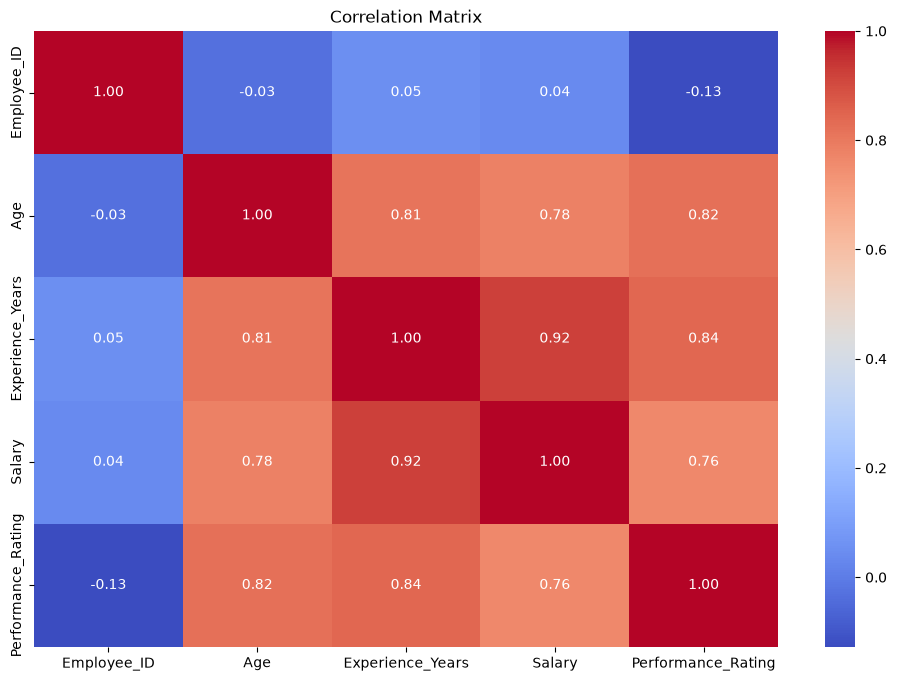

In [19]:
correlation_matrix = df[numerical_columns].corr()

print(correlation_matrix)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

### Feature Relationships

In [ ]:
Different combinations of features should be examined.

Examples:
    
Feature combination	Analysis

Age vs Salary	              Numerical vs Numerical
Experience vs Salary	      Numerical vs Numerical
Department vs Salary	      Categorical vs Numerical
Gender vs Churn	              Categorical vs Categorical
Product Category vs Sales	  Categorical vs Numerical

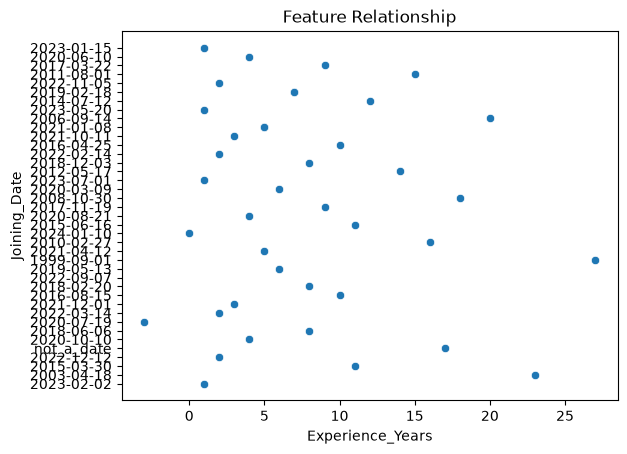

In [21]:
sns.scatterplot(
    data=df,
    x="Experience_Years",
    y="Joining_Date"
)

plt.title("Feature Relationship")
plt.show()

### Important Patterns

Identify meaningful observations such as:

- Features that strongly relate to the target
- Groups with significantly different outcomes
- Features that increase or decrease together
- Unusual combinations of feature values
- Potentially redundant features
- Important customer or business segments

### Visualization Findings

In [ ]:

Visualizations help communicate patterns that may not be immediately clear from numerical summaries.

This section should summarize the most important findings from previous visualization notebooks

Visualization	   What to document

Histogram	     Distribution shape, skewness, peaks
KDE Plot	     Density and distribution patterns
Box Plot	     Median, spread, potential outliers
Bar Chart	     Category frequencies
Count Plot       Class imbalance
Scatter Plot	 Relationships and clusters
Heatmap      	 Correlations

### Potential Data Problems

#### Missing-Value Problems

Potential issues:

- Some features contain missing values.
- Certain columns have a high percentage of missing values.
- Missing values may affect statistical calculations.
- Important target values may be missing.

#### Duplicate Problems

Potential issues:

- Completely duplicated records.
- Repeated observations.
- Potentially duplicated records with different identifiers.

#### Outlier Problems

Potential issues:

- Extreme numerical values.
- Highly skewed numerical features.
- Unusual observations.
- Potential measurement errors.

#### Categorical Data Problems

Potential issues:

- Rare categories.
- High-cardinality features
- Inconsistent category names
- Imbalanced target classes
- Unexpected category values

#### Distribution Problems

Potential issues:

- Strong positive or negative skewness.
- Non-normal distributions.
- Large differences in feature scales.
- Extreme values affecting distributions

#### Multicollinearity Problems

Potential issues:

- Highly correlated numerical features
- Redundant features
- Multiple features containing similar information

### Conclusion

Exploratory Data Analysis is an important step in the data science and machine learning workflow.

Through this sprint, we have:

1. Understood the dataset structure and domain
2. Examined missing values and duplicate records
3. Identified potentially invalid values and data-type issues
4. Analyzed central tendency and dispersion
5. Examined feature distributions and potential outliers
6. Investigated correlations and feature relationships
7. Identified important patterns through visualizations
8. Documented potential problems affecting future analysis
9. Prepared recommendations for the preprocessing stage